## Alternate subquestion (tomi)

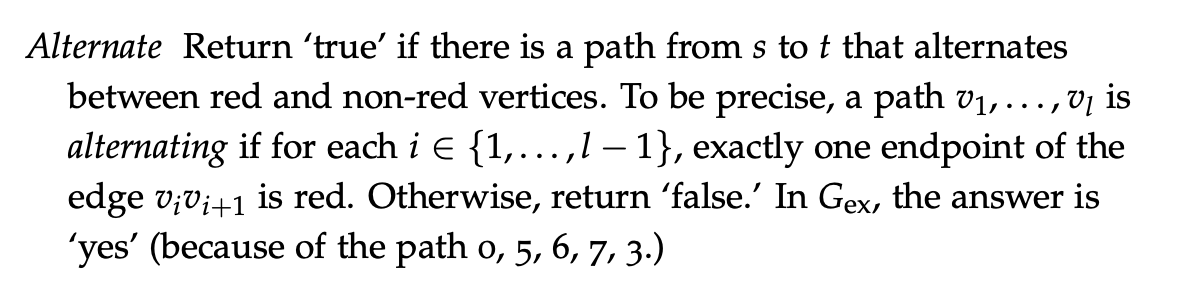

In other words, the objective is to find a path from the source to the sink that does NOT have any black-black or red-red edges. 

Red-black-red-black is the only possible for path.

See example:

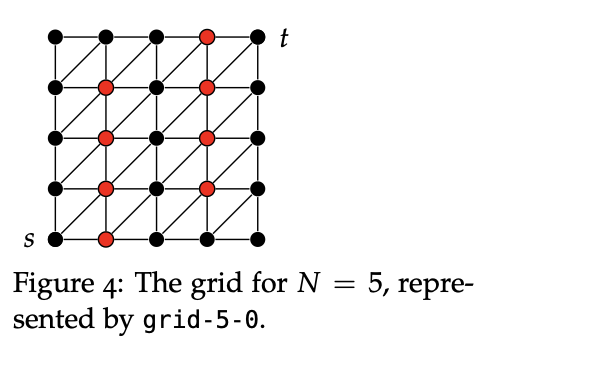

Here the diagonal path from s to t is valid.

- It does NOT have to be the shortest path.
- The algorithm is tested on simple graphs, meaning no self-loops or duplicate edges between vertices. 
- Only simple paths are allowed

In [1]:
%pip install itu.algs4

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [2]:
from collections import deque
from pathlib import Path
from build_graphs import parse_graph

print(Path.cwd())

/Users/tobias/Desktop/data_science/masters/Autumn 2026 - Semester 1/Algorithm Design/Red Scare/red_scare_group_t/src


In [3]:
def alternate(adj_list, red_vertices, s, t):

    if s == t:                                              # to check for the case when s and t are the same vertex 
        return True

    seen = {s} 
    queue = deque([s])

    while queue:                                            #While there are still vertices in the queue

        current = queue.popleft()
        red_vertex = current in red_vertices                #check in red_vertices if the current vertex is red or not

        for neighbour in adj_list[current]:                 #Check all the neighbours of the current vertex
            if neighbour in seen:                           #skip if already visited
                continue
            if (neighbour in red_vertices) == red_vertex:   #Main condition: if current vertex is red, neighbour must be non-red and vice versa
                continue                                    #expression (neighbour in red_vertices) == red_vertex evaluates to True if both are red or both are non-red, which we want to skip
            if neighbour == t:                              #Ends function if we reach t and return True.
                return True
            seen.add(neighbour)
            queue.append(neighbour) 
    return False                                            #once queue is empty and we have not reached t, we return False


### Testing: def_alternate

- Seems to check out

In [4]:
DATA = Path("../red-scare/data")
HANDMADE = Path("../red-scare/instance-generators/handmade")

tests = [
    (DATA / "G-ex.txt", True),
    (DATA / "P3.txt", True),
    (HANDMADE / "K3-0.txt", True),
    (HANDMADE / "K3-1.txt", True),
    ]
for path, expected in tests:
    adj_list, reds, s, t, directed = parse_graph(path)
    result = alternate(adj_list, reds, s, t)
    print(path.stem, result, result == expected)

G-ex True True
P3 True True
K3-0 True True
K3-1 True True


### Results: 
1. tested on all graphs in src
2. sort results by graphs with most vertices
3. get run-time for top 3 graphs

In [5]:
from prepare_results import all_results, report_500_plus
import os

if Path.cwd().name == "src":
    os.chdir("..")

results = all_results(alternate)
print(len(results), "instances,", sum(r[2] for r in results), "true")

report_500_plus(alternate)

154 instances, 46 true
bht: n = 5757, result = False
common-1-1000: n = 1000, result = False
common-1-1500: n = 1500, result = False
common-1-2000: n = 2000, result = False
common-1-2500: n = 2500, result = False
common-1-3000: n = 3000, result = False
common-1-3500: n = 3500, result = False
common-1-4000: n = 4000, result = False
common-1-4500: n = 4500, result = True
common-1-500: n = 500, result = False
common-1-5000: n = 5000, result = True
common-1-5757: n = 5757, result = True
common-2-1000: n = 1000, result = True
common-2-1500: n = 1500, result = True
common-2-2000: n = 2000, result = True
common-2-2500: n = 2500, result = True
common-2-3000: n = 3000, result = True
common-2-3500: n = 3500, result = True
common-2-4000: n = 4000, result = True
common-2-4500: n = 4500, result = True
common-2-500: n = 500, result = True
common-2-5000: n = 5000, result = True
common-2-5757: n = 5757, result = True
gnm-1000-1500-0: n = 1000, result = False
gnm-1000-1500-1: n = 1000, result = False
g

In [6]:
import pandas as pd

df = pd.DataFrame(all_results(alternate), columns=["name", "n", "alternate"])
df[df["n"] >= 500].sort_values(by="n", ascending=False)

,name,n,alternate
134,wall-n-10000,80000,False
150,wall-z-10000,70001,False
142,wall-p-10000,60002,False
133,wall-n-1000,8000,False
149,wall-z-1000,7001,False
...,...,...,...
82,increase-n500-1,500,True
15,common-1-500,500,False
83,increase-n500-2,500,True
30,common-2-500,500,True


### Run-time

In [9]:
#Only checking the three largest graphs

import time

for name in ["wall-n-10000", "wall-z-10000", "wall-p-10000"]:
    adj_list, reds, s, t, directed = parse_graph(Path("red-scare/data") / f"{name}.txt")
    start = time.perf_counter()
    alternate(adj_list, reds, s, t)
    print(name, "n =", len(adj_list), "seconds =", time.perf_counter() - start)

wall-n-10000 n = 80000 seconds = 1.5042000029552582e-05
wall-z-10000 n = 70001 seconds = 1.5708000034919678e-05
wall-p-10000 n = 60002 seconds = 1.754200002324069e-05
